<a href="https://colab.research.google.com/github/abhisat16/PCOS-Project/blob/main/pcos_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting PCOS from Clinical Data

I am building a model that predicts a PCOS diagnosis from routine clinical, hormonal and ultrasound data of 541 women from 10 hospitals in Kerala, India.

**My problem statement:** Using routinely collected clinical data, I predict whether a woman has PCOS, and I identify which clinical features matter most.

**My approach:**
1. I load the data and take a first look.
2. I clean the data: column names, data types, missing values and impossible values.
3. I explore the data with summary statistics and charts.
4. I choose features for two models: one with all features, and one without the Rotterdam diagnostic criteria.
5. I train logistic regression and random forest models.
6. I validate and evaluate them with a train/test split, cross-validation, AUC, ROC curves and confusion matrices.
7. I document my findings.

**Data source:** Kottarathil P. *Polycystic ovary syndrome (PCOS)*, Kaggle, 2020.

## Step 1: Loading the data

I am connecting my Google Drive so I can read the dataset stored in my project folder.

In [4]:
# I am connecting Google Drive and moving into my project folder
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/pcos-project')
print(os.listdir())   # I am checking that the Excel file is here

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['PCOS_data_without_infertility.xlsx']


I am importing the libraries I need for data handling (pandas, NumPy) and for charts (Matplotlib, Seaborn).

In [5]:
# I am importing my libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

I am checking which sheets the Excel file contains, so I load the correct one.

In [6]:
# I am loading the data and checking how many rows and columns it has
df = pd.read_excel("PCOS_data_without_infertility.xlsx", sheet_name="Full_new")
print(df.shape)
df.head()

(541, 45)


,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Unnamed: 44
0,1,1,0,28,44.6,152.0,19.300000,15,78,22,...,1.0,0,110,80,3,3,18.0,18.0,8.5,NaN
1,2,2,0,36,65.0,161.5,24.921163,15,74,20,...,0.0,0,120,70,3,5,15.0,14.0,3.7,NaN
2,3,3,1,33,68.8,165.0,25.270891,11,72,18,...,1.0,0,120,80,13,15,18.0,20.0,10.0,NaN
3,4,4,0,37,65.0,148.0,29.674945,13,72,20,...,0.0,0,120,70,2,2,15.0,14.0,7.5,NaN
4,5,5,0,25,52.0,161.0,20.060954,11,72,18,...,0.0,0,120,80,3,4,16.0,14.0,7.0,NaN


I am checking each column's data type and how many values are missing.


In [7]:
# I am inspecting data types and non-missing counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 45 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sl. No                  541 non-null    int64  
 1   Patient File No.        541 non-null    int64  
 2   PCOS (Y/N)              541 non-null    int64  
 3    Age (yrs)              541 non-null    int64  
 4   Weight (Kg)             541 non-null    float64
 5   Height(Cm)              541 non-null    float64
 6   BMI                     541 non-null    float64
 7   Blood Group             541 non-null    int64  
 8   Pulse rate(bpm)         541 non-null    int64  
 9   RR (breaths/min)        541 non-null    int64  
 10  Hb(g/dl)                541 non-null    float64
 11  Cycle(R/I)              541 non-null    int64  
 12  Cycle length(days)      541 non-null    int64  
 13  Marraige Status (Yrs)   540 non-null    float64
 14  Pregnant(Y/N)           541 non-null    in

I am counting how many women in the dataset have PCOS and how many do not.

In [8]:
# I am counting PCOS (1) and non-PCOS (0) cases
df["PCOS (Y/N)"].value_counts()

,count
PCOS (Y/N),
0,364
1,177


## Step 2: Cleaning the data

Real clinical data is messy. In this step I fix column names, remove columns I do not need, convert text to numbers, handle missing values, and check for impossible values. I record every decision so my work is reproducible.

### 2.1 Fixing column names

I am removing hidden spaces at the start and end of column names, because they cause errors when I refer to a column.

In [9]:
# I am stripping extra spaces from column names
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['Sl. No', 'Patient File No.', 'PCOS (Y/N)', 'Age (yrs)', 'Weight (Kg)', 'Height(Cm)', 'BMI', 'Blood Group', 'Pulse rate(bpm)', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', 'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)', 'Unnamed: 44']


### 2.2 Removing columns I do not need

I am removing ID columns (they carry no clinical meaning) and any column that is completely empty.

In [10]:
# I am finding columns that are completely empty
empty_cols = df.columns[df.isna().all()].tolist()
print("Empty columns:", empty_cols)

# I am dropping ID columns and empty columns
df = df.drop(columns=["Sl. No", "Patient File No."] + empty_cols)
print(df.shape)

Empty columns: []
(541, 43)


### 2.3 Finding text inside number columns

Some columns should hold numbers but pandas reads them as text (dtype "object"). I am finding exactly which values are not numbers.

In [11]:
# I am listing columns stored as text
text_cols = df.select_dtypes(include="object").columns.tolist()
print("Text columns:", text_cols)

# I am showing the values in each text column that cannot be read as a number
for col in text_cols:
    bad = df[col][pd.to_numeric(df[col], errors="coerce").isna() & df[col].notna()]
    print(f"\n{col}: {len(bad)} bad value(s)")
    print(bad.unique())

Text columns: ['II    beta-HCG(mIU/mL)', 'AMH(ng/mL)', 'Unnamed: 44']

II    beta-HCG(mIU/mL): 1 bad value(s)
['1.99.']

AMH(ng/mL): 1 bad value(s)
['a']

Unnamed: 44: 1 bad value(s)
['.']


I am converting these columns to numbers. Any value that is not a valid number becomes missing (NaN), and I handle it in the next step.

In [12]:
# I am converting text columns to numbers
for col in text_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.dtypes.value_counts()   # I am checking that no text columns remain

,count
float64,22
int64,21


### 2.4 Handling missing values

I am counting the missing values in each column.

In [13]:
# I am counting missing values per column
missing = df.isna().sum()
missing[missing > 0]

,0
Marraige Status (Yrs),1
II beta-HCG(mIU/mL),1
AMH(ng/mL),1
Fast food (Y/N),1
Unnamed: 44,540


Only a few values are missing, so I fill each one with the column's median. I use the median instead of the mean because clinical values like hormones are often skewed, and the median is not pulled by extreme values.

In [14]:
# I am filling missing values with each column's median
for col in missing[missing > 0].index:
    df[col] = df[col].fillna(df[col].median())

print("Missing values left:", df.isna().sum().sum())

Missing values left: 0


### 2.5 Checking for impossible values

I am looking at the minimum and maximum of every column to spot values that make no clinical sense.

In [15]:
# I am showing summary statistics for every column
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PCOS (Y/N),541.0,0.327172,0.469615,0.000000,0.000000,0.000000,1.000000,1.000000
Age (yrs),541.0,31.430684,5.411006,20.000000,28.000000,31.000000,35.000000,48.000000
Weight (Kg),541.0,59.637153,11.028287,31.000000,52.000000,59.000000,65.000000,108.000000
Height(Cm),541.0,156.484835,6.033545,137.000000,152.000000,156.000000,160.000000,180.000000
BMI,541.0,24.311285,4.056399,12.417882,21.641274,24.238227,26.634958,38.900000
Blood Group,541.0,13.802218,1.840812,11.000000,13.000000,14.000000,15.000000,18.000000
Pulse rate(bpm),541.0,73.247689,4.430285,13.000000,72.000000,72.000000,74.000000,82.000000
RR (breaths/min),541.0,19.243993,1.688629,16.000000,18.000000,18.000000,20.000000,28.000000
Hb(g/dl),541.0,11.160037,0.866904,8.500000,10.500000,11.000000,11.700000,14.800000
Cycle(R/I),541.0,2.560074,0.901950,2.000000,2.000000,2.000000,4.000000,5.000000


### 2.6 Flagging clinically impossible values

I am setting broad plausibility limits for each clinical variable, based on my clinical knowledge. These are not normal ranges; they are the limits beyond which a value is almost certainly a data-entry error.

In [16]:
# I am defining plausible (not normal) limits for each variable: (lowest, highest)
limits = {
    "Pulse rate(bpm)":      (40, 150),
    "RR (breaths/min)":     (8, 40),
    "BP _Systolic (mmHg)":  (70, 200),
    "BP _Diastolic (mmHg)": (40, 130),
    "BMI":                  (12, 60),
    "Hb(g/dl)":             (5, 20),
    "FSH(mIU/mL)":          (0, 200),
    "LH(mIU/mL)":           (0, 200),
    "AMH(ng/mL)":           (0, 50),
    "TSH (mIU/L)":          (0, 50),
    "PRL(ng/mL)":           (0, 500),
    "Vit D3 (ng/mL)":       (0, 200),
    "RBS(mg/dl)":           (40, 500),
    "Endometrium (mm)":     (0, 30),
}

# I am listing every value outside its limits
flags = []
for col, (low, high) in limits.items():
    if col not in df.columns:
        print(f"Column not found, check its name: {col}")
        continue
    out = df[(df[col] < low) | (df[col] > high)][col]
    for idx, val in out.items():
        flags.append({"row": idx, "column": col, "value": val, "allowed": f"{low}-{high}"})

flags = pd.DataFrame(flags)
print(len(flags), "impossible values found")
flags

10 impossible values found


,row,column,value,allowed
0,223,Pulse rate(bpm),18.00,40-150
1,296,Pulse rate(bpm),13.00,40-150
2,161,BP _Systolic (mmHg),12.00,70-200
3,200,BP _Diastolic (mmHg),8.00,40-130
4,329,FSH(mIU/mL),5052.00,0-200
5,455,LH(mIU/mL),2018.00,0-200
6,267,AMH(ng/mL),66.00,0-50
7,37,TSH (mIU/L),65.00,0-50
8,191,Vit D3 (ng/mL),6014.66,0-200
9,195,Vit D3 (ng/mL),5418.60,0-200


I reviewed each flagged value clinically:

| Row | Column | Value | Decision | Reason |
|---|---|---|---|---|
| 161 | Systolic BP | 12 | Corrected to 120 | Missing zero (typing error) |
| 200 | Diastolic BP | 8 | Corrected to 80 | Missing zero (typing error) |
| 223, 296 | Pulse | 18, 13 | Set to missing | Not compatible with life |
| 329 | FSH | 5052 | Set to missing | Impossible value |
| 455 | LH | 2018 | Set to missing | Looks like a year typed by mistake |
| 191, 195 | Vitamin D3 | 6014.66, 5418.60 | Set to missing | Impossible value |
| 267 | AMH | 66 | Kept | Very high AMH occurs in severe PCOS |
| 37 | TSH | 65 | Kept | Possible in overt hypothyroidism |

In [17]:
# I am correcting the two blood pressure typing errors
df.loc[161, "BP _Systolic (mmHg)"] = 120
df.loc[200, "BP _Diastolic (mmHg)"] = 80

# I am widening the AMH and TSH limits, because the high values I found are clinically possible
limits["AMH(ng/mL)"] = (0, 100)
limits["TSH (mIU/L)"] = (0, 100)

# I am setting the remaining impossible values to missing and filling them with the median
for col, (low, high) in limits.items():
    bad = (df[col] < low) | (df[col] > high)
    df.loc[bad, col] = np.nan
    df[col] = df[col].fillna(df[col].median())

# I am confirming that no impossible values remain
remaining = sum(((df[c] < lo) | (df[c] > hi)).sum() for c, (lo, hi) in limits.items())
print("Impossible values remaining:", remaining)

Impossible values remaining: 0


In [18]:
# I am checking whether the high-AMH and high-TSH patients have PCOS
df.loc[[267, 37], ["PCOS (Y/N)", "AMH(ng/mL)", "TSH (mIU/L)"]]

,PCOS (Y/N),AMH(ng/mL),TSH (mIU/L)
267,1,66.00,1.71
37,0,0.88,65.00


I checked the two extreme values I kept. The patient with AMH 66 ng/mL has PCOS, which is consistent with the high follicle count in polycystic ovaries. The patient with TSH 65 mIU/L does not have PCOS and has a normal AMH, which is consistent with overt hypothyroidism, a condition that must be excluded before diagnosing PCOS. Both values are clinically genuine, so I kept them.


### 2.7 Recalculating derived columns

FSH/LH and the waist-hip ratio are calculated from other columns. Because I changed some of the original values, I recalculate them so they stay consistent.

In [19]:
# I am recalculating ratio columns from the cleaned values
df["FSH/LH"] = df["FSH(mIU/mL)"] / df["LH(mIU/mL)"].replace(0, np.nan)
df["FSH/LH"] = df["FSH/LH"].fillna(df["FSH/LH"].median())
df["Waist:Hip Ratio"] = df["Waist(inch)"] / df["Hip(inch)"]

### 2.8 Checking coded columns

I am checking how the categorical columns are coded, so I know what each number means.

In [20]:
# I am checking the codes used in the cycle column
print(df["Cycle(R/I)"].value_counts())

Cycle(R/I)
2    390
4    150
5      1
Name: count, dtype: int64


The cycle column uses 2 for regular and 4 for irregular. I am converting it to a clear 0/1 column (1 = irregular) so it reads like the other yes/no columns.

In [21]:
# I am recoding the cycle column: 1 = irregular, 0 = regular
df["Irregular cycle"] = (df["Cycle(R/I)"] == 4).astype(int)
df = df.drop(columns=["Cycle(R/I)"])
df["Irregular cycle"].value_counts()

,count
Irregular cycle,
0,391
1,150


In [22]:
# I am checking the original cycle codes in the raw file
raw = pd.read_excel("PCOS_data_without_infertility.xlsx", sheet_name="Full_new")
raw.columns = raw.columns.str.strip()
raw["Cycle(R/I)"].value_counts()

,count
Cycle(R/I),
2,390
4,150
5,1


In [23]:
# I am inspecting the patient with the undocumented cycle code 5
row5 = raw.index[raw["Cycle(R/I)"] == 5]
raw.loc[row5, ["PCOS (Y/N)", "Cycle(R/I)", "Cycle length(days)"]]

,PCOS (Y/N),Cycle(R/I),Cycle length(days)
512,1,5,7


This patient has PCOS, but I did not use her diagnosis to fill the value, because filling a predictor using the outcome would leak information into the model.

### 2.9 Saving the clean dataset

I am saving the cleaned data as a new file, so the original stays untouched and my steps are reproducible.

In [24]:
# I am saving the cleaned dataset and confirming its final state
df.to_csv("pcos_clean.csv", index=False)
print(df.shape)
print("Missing values:", df.isna().sum().sum())

(541, 43)
Missing values: 0


In [28]:
# I am listing the final columns to check that nothing unwanted remains
print(df.columns.tolist())

['PCOS (Y/N)', 'Age (yrs)', 'Weight (Kg)', 'Height(Cm)', 'BMI', 'Blood Group', 'Pulse rate(bpm)', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', 'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)', 'Irregular cycle']


In [29]:
# I am removing the leftover Excel column (if it is still there) and saving again
df = df.drop(columns=["Unnamed: 44"], errors="ignore")
df.to_csv("pcos_clean.csv", index=False)
print(df.shape)

(541, 42)


## Step 3: Exploratory data analysis

In this step I describe the data and compare women with and without PCOS, using summary statistics and charts.

### 3.1 How many women have PCOS?

I am checking the balance between the two groups, because it affects how I evaluate my models later.

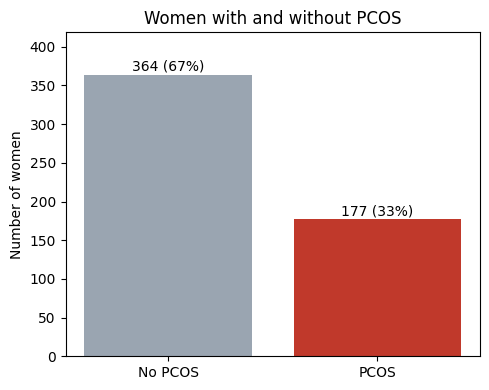

In [45]:
# I am plotting the number of women with and without PCOS
counts = df["PCOS (Y/N)"].map({0: "No PCOS", 1: "PCOS"}).value_counts()

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(counts.index, counts.values, color=["#9aa5b1", "#c0392b"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, f"{v} ({v / len(df):.0%})", ha="center")
ax.set_title("Women with and without PCOS")
ax.set_ylabel("Number of women")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig("fig1_pcos_counts.png", dpi=150)
plt.show()

### 3.2 Comparing key clinical values between the groups

I am comparing the median and interquartile range (IQR) of key clinical variables in women with and without PCOS. I use the median and IQR because many hormone values are skewed. I use the Mann-Whitney U test to check whether each difference is statistically significant, because it does not assume a normal distribution.

In [46]:
# I am comparing key variables between PCOS and non-PCOS women
from scipy.stats import mannwhitneyu

key_vars = ["Age (yrs)", "BMI", "AMH(ng/mL)", "LH(mIU/mL)", "FSH(mIU/mL)", "PRG(ng/mL)",
            "Follicle No. (L)", "Follicle No. (R)", "Endometrium (mm)",
            "Waist:Hip Ratio", "TSH (mIU/L)", "PRL(ng/mL)", "Vit D3 (ng/mL)", "RBS(mg/dl)"]

rows = []
for col in key_vars:
    pcos = df.loc[df["PCOS (Y/N)"] == 1, col]
    no_pcos = df.loc[df["PCOS (Y/N)"] == 0, col]
    p = mannwhitneyu(pcos, no_pcos).pvalue
    rows.append({
        "Variable": col,
        "No PCOS: median (IQR)": f"{no_pcos.median():.2f} ({no_pcos.quantile(.25):.2f}-{no_pcos.quantile(.75):.2f})",
        "PCOS: median (IQR)": f"{pcos.median():.2f} ({pcos.quantile(.25):.2f}-{pcos.quantile(.75):.2f})",
        "p-value": f"{p:.3f}" if p >= 0.001 else "<0.001",
    })

summary = pd.DataFrame(rows)
summary

,Variable,No PCOS: median (IQR),PCOS: median (IQR),p-value
0,Age (yrs),32.00 (28.00-36.00),29.00 (27.00-33.00),<0.001
1,BMI,23.60 (21.36-26.09),25.10 (23.01-28.30),<0.001
2,AMH(ng/mL),3.21 (1.90-5.30),5.90 (2.60-10.20),<0.001
3,LH(mIU/mL),2.30 (1.03-3.60),2.22 (1.00-4.30),0.413
4,FSH(mIU/mL),4.99 (3.40-6.54),4.48 (3.23-5.76),0.008
5,PRG(ng/mL),0.31 (0.25-0.46),0.32 (0.25-0.43),0.386
6,Follicle No. (L),4.00 (2.00-6.00),10.00 (7.00-12.00),<0.001
7,Follicle No. (R),4.00 (2.00-7.00),11.00 (8.00-13.00),<0.001
8,Endometrium (mm),8.30 (7.00-9.50),8.90 (7.60-10.00),0.005
9,Waist:Hip Ratio,0.89 (0.86-0.93),0.90 (0.86-0.93),0.652


**Group comparison:** Compared with women without PCOS, women with PCOS were younger (median age 29 vs 32 years) and had a higher BMI (25.1 vs 23.6), nearly double the AMH (5.9 vs 3.2 ng/mL), and more than twice the follicle count in each ovary (10–11 vs 4); all p < 0.001. FSH was slightly lower (4.48 vs 4.99 mIU/mL, p = 0.008) and the endometrium slightly thicker (8.9 vs 8.3 mm, p = 0.005).

LH, progesterone, TSH, prolactin, vitamin D, random blood sugar and waist-hip ratio did not differ significantly. The lack of LH difference is unexpected, because raised LH is a recognised feature of PCOS. Progesterone was low in both groups (median 0.3 ng/mL), suggesting most samples were taken in the follicular phase. The cycle day of sampling is not recorded, which limits how I can interpret these hormones.

### 3.3 Distribution of key variables by PCOS status

I am using box plots to see how follicle count, AMH, BMI and progesterone differ between the groups.

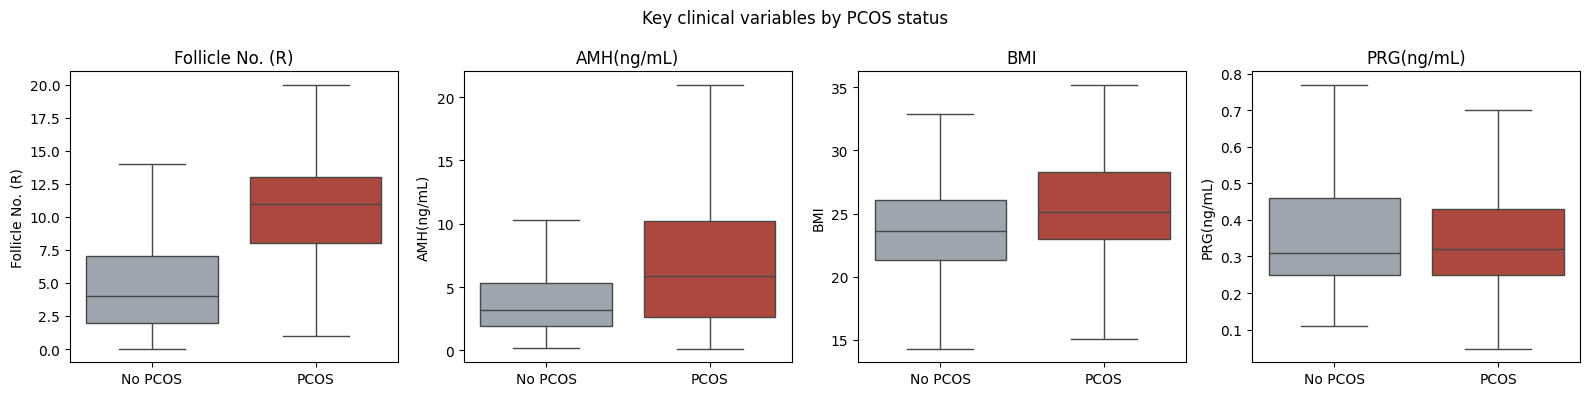

In [47]:
# I am drawing box plots of four key variables by PCOS status
plot_vars = ["Follicle No. (R)", "AMH(ng/mL)", "BMI", "PRG(ng/mL)"]
plot_df = df.assign(Group=df["PCOS (Y/N)"].map({0: "No PCOS", 1: "PCOS"}))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, plot_vars):
    sns.boxplot(data=plot_df, x="Group", y=col, hue="Group", order=["No PCOS", "PCOS"],
                palette={"No PCOS": "#9aa5b1", "PCOS": "#c0392b"},
                legend=False, showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Key clinical variables by PCOS status")
plt.tight_layout()
plt.savefig("fig2_boxplots.png", dpi=150)
plt.show()

### 3.4 Symptoms and lifestyle by PCOS status

I am comparing how common each symptom and lifestyle factor is in women with and without PCOS.

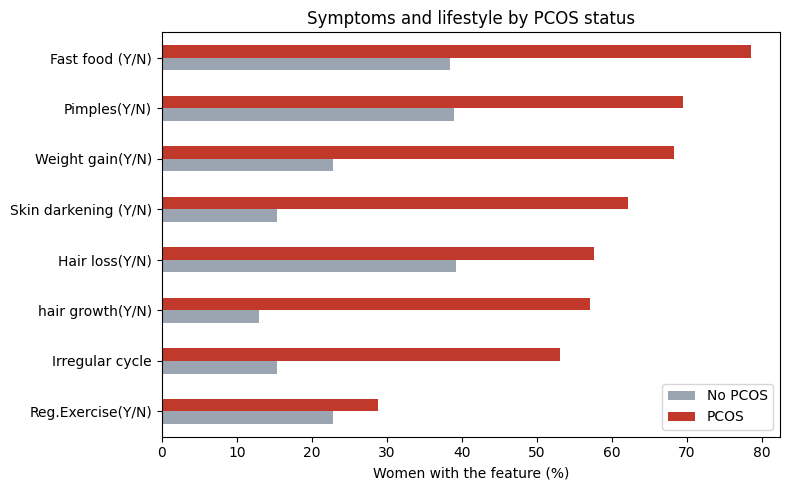

,No PCOS,PCOS
Reg.Exercise(Y/N),22.8,28.8
Irregular cycle,15.4,53.1
hair growth(Y/N),12.9,57.1
Hair loss(Y/N),39.3,57.6
Skin darkening (Y/N),15.4,62.1
Weight gain(Y/N),22.8,68.4
Pimples(Y/N),39.0,69.5
Fast food (Y/N),38.5,78.5


In [48]:
# I am comparing the percentage of women with each symptom in both groups
yes_no = ["Irregular cycle", "Weight gain(Y/N)", "hair growth(Y/N)", "Skin darkening (Y/N)",
          "Hair loss(Y/N)", "Pimples(Y/N)", "Fast food (Y/N)", "Reg.Exercise(Y/N)"]

pct = df.groupby("PCOS (Y/N)")[yes_no].mean().T * 100
pct.columns = ["No PCOS", "PCOS"]
pct = pct.sort_values("PCOS")

ax = pct.plot(kind="barh", figsize=(8, 5), color=["#9aa5b1", "#c0392b"])
ax.set_xlabel("Women with the feature (%)")
ax.set_title("Symptoms and lifestyle by PCOS status")
plt.tight_layout()
plt.savefig("fig3_symptoms.png", dpi=150)
plt.show()
pct.round(1)

**Symptoms and lifestyle:** Weight gain (68% vs 23%), skin darkening (62% vs 15%), excess hair growth (57% vs 13%) and irregular cycles (53% vs 15%) were all far more common in women with PCOS, consistent with insulin resistance and hyperandrogenism. Notably, only about half of the women with PCOS reported irregular cycles, which fits the Rotterdam definition: a woman can be diagnosed with any two of the three criteria.

Fast food intake was twice as common in women with PCOS (79% vs 39%). Regular exercise was slightly more common in women with PCOS (29% vs 23%), possibly because women already diagnosed are advised to exercise (reverse causation). These lifestyle answers are self-reported.

### 3.5 Which variables are most related to PCOS?

I am calculating the correlation of every variable with the PCOS diagnosis, to see which features carry the most information.

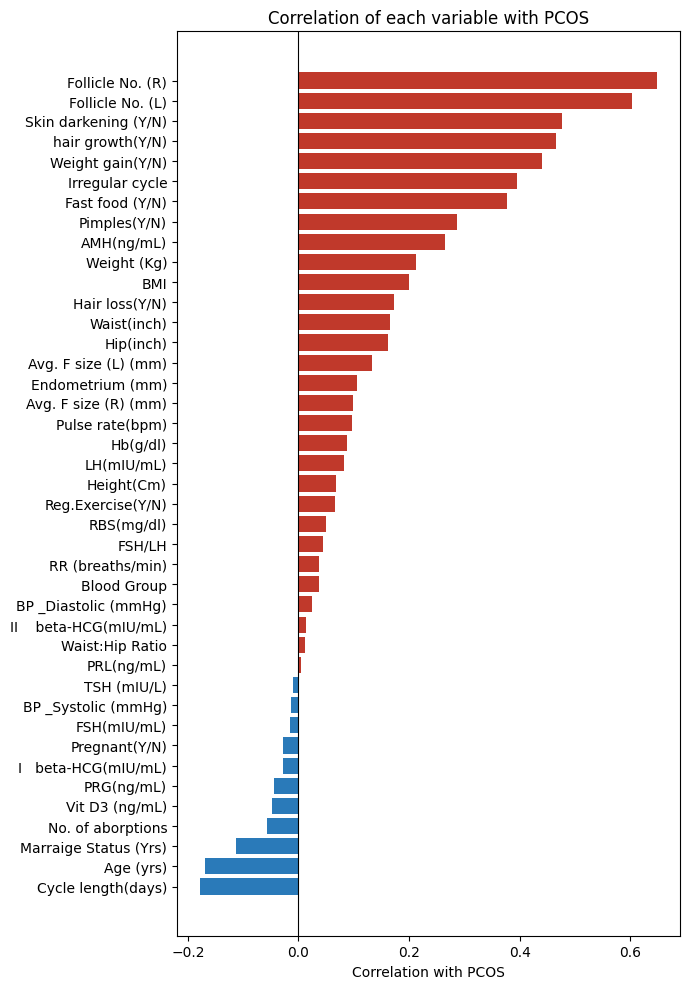

In [49]:
# I am ranking variables by their correlation with PCOS
corr = df.corr(numeric_only=True)["PCOS (Y/N)"].drop("PCOS (Y/N)").sort_values()

fig, ax = plt.subplots(figsize=(7, 10))
colors = ["#c0392b" if v > 0 else "#2a7ab9" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with PCOS")
ax.set_title("Correlation of each variable with PCOS")
plt.tight_layout()
plt.savefig("fig4_correlation.png", dpi=150)
plt.show()

## Step 4: Preparing features

I am building two feature sets:

- **Model A (all features):** every clinical variable.
- **Model B (screening model):** I remove the Rotterdam diagnostic criteria (cycle irregularity, signs of hyperandrogenism, and ultrasound follicle findings). The doctors used these to make the diagnosis, so including them makes the prediction partly circular. Model B tests whether PCOS can be flagged from history, body measurements and blood tests before an ultrasound.

I also remove Blood Group, because it is a coded category with no known link to PCOS.

In [30]:
# I am separating the outcome (y) from the predictors
y = df["PCOS (Y/N)"]

# I am removing the outcome and blood group from the predictors
X_all = df.drop(columns=["PCOS (Y/N)", "Blood Group"])

# I am listing the Rotterdam criteria variables
rotterdam = ["Irregular cycle", "Cycle length(days)",          # ovulatory dysfunction
             "hair growth(Y/N)", "Pimples(Y/N)", "Hair loss(Y/N)",  # hyperandrogenism
             "Follicle No. (L)", "Follicle No. (R)",            # polycystic ovaries
             "Avg. F size (L) (mm)", "Avg. F size (R) (mm)"]

X_screen = X_all.drop(columns=rotterdam)

print("Model A features:", X_all.shape[1])
print("Model B features:", X_screen.shape[1])

Model A features: 40
Model B features: 31


### 4.1 Splitting into training and test sets

I am splitting the data into 80% for training and 20% for testing. I use a stratified split so both sets keep the same proportion of PCOS cases. I set random_state so my split is the same every time I run the notebook. The test set stays untouched until the final evaluation.

In [31]:
# I am splitting the data, keeping the PCOS proportion the same in both sets
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    df.index, test_size=0.2, stratify=y, random_state=42)

y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("Training women:", len(train_idx), "| Test women:", len(test_idx))
print(f"PCOS rate - train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

Training women: 432 | Test women: 109
PCOS rate - train: 32.6% | test: 33.0%


## Step 5: Training the models

I am training two types of model on each feature set:

- **Logistic regression:** a standard statistical model for yes/no outcomes. I scale the features first, because the variables are on very different scales (for example, AMH in ng/mL vs RBS in mg/dL).
- **Random forest:** a machine learning model that combines many decision trees and can capture non-linear patterns. It does not need scaling.

I use a Pipeline so that scaling is learned only from the training data, which prevents information leaking from the test set.

In [32]:
# I am setting up my two model types
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def make_models():
    return {
        "Logistic regression": Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000))]),
        "Random forest": RandomForestClassifier(n_estimators=300, random_state=42),
    }

feature_sets = {"Model A (all features)": X_all, "Model B (screening)": X_screen}

### 5.1 Cross-validation on the training set

I am using 5-fold stratified cross-validation. I split the training data into 5 parts, train each model on 4 parts and test it on the 5th, and repeat this five times. This gives a more reliable estimate than a single split. I measure performance with AUC (area under the ROC curve), where 0.5 is chance and 1.0 is perfect.

In [33]:
# I am comparing all four combinations with 5-fold cross-validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for set_name, X in feature_sets.items():
    for model_name, model in make_models().items():
        scores = cross_val_score(model, X.loc[train_idx], y_train, cv=cv, scoring="roc_auc")
        cv_results.append({"Feature set": set_name, "Model": model_name,
                           "CV AUC (mean)": round(scores.mean(), 3),
                           "CV AUC (SD)": round(scores.std(), 3)})

pd.DataFrame(cv_results)

,Feature set,Model,CV AUC (mean),CV AUC (SD)
0,Model A (all features),Logistic regression,0.934,0.016
1,Model A (all features),Random forest,0.957,0.019
2,Model B (screening),Logistic regression,0.819,0.042
3,Model B (screening),Random forest,0.856,0.037


**Cross-validation results:** Model A reaches a very high AUC (0.93–0.96), as expected, because it includes the Rotterdam diagnostic criteria. Model B, which excludes all cycle, hyperandrogenism and ultrasound features, still achieves a good AUC (0.82–0.86). This suggests that body measurements and blood tests could help flag women who need further PCOS assessment. Random forest performs slightly better than logistic regression in both feature sets, suggesting some non-linear relationships between the features. Model B's results vary more across folds, because it relies on weaker signals.

## Step 6: Final evaluation on the test set

I am training each model on all 432 training women and testing it once on the 109 women it has never seen. This gives an honest estimate of how the model would perform on new patients.

In [34]:
# I am training on the full training set and testing once on the test set
from sklearn.metrics import roc_auc_score, accuracy_score

test_results = []
fitted = {}     # I am storing the trained models for later steps
probs = {}      # I am storing each model's predicted probabilities

for set_name, X in feature_sets.items():
    for model_name, model in make_models().items():
        model.fit(X.loc[train_idx], y_train)
        p = model.predict_proba(X.loc[test_idx])[:, 1]   # probability of PCOS
        key = f"{set_name} - {model_name}"
        fitted[key], probs[key] = model, p
        test_results.append({"Feature set": set_name, "Model": model_name,
                             "Test AUC": round(roc_auc_score(y_test, p), 3),
                             "Test accuracy": round(accuracy_score(y_test, (p >= 0.5).astype(int)), 3)})

pd.DataFrame(test_results)

,Feature set,Model,Test AUC,Test accuracy
0,Model A (all features),Logistic regression,0.935,0.881
1,Model A (all features),Random forest,0.928,0.936
2,Model B (screening),Logistic regression,0.806,0.844
3,Model B (screening),Random forest,0.811,0.789


**Test results:** Test AUCs are close to the cross-validation AUCs, so the models generalise well and are not overfitted. On the test set, logistic regression and random forest perform almost equally (Model A: 0.935 vs 0.928; Model B: 0.806 vs 0.811). With only 109 test women, differences of this size are not meaningful. Because the two models perform similarly, I prefer logistic regression for clinical use, because its predictions are easier to interpret. Accuracy differs more than AUC between the models because accuracy depends on the chosen 0.5 cut-off, while AUC does not.

### 6.2 ROC curves

I am plotting ROC curves for all four models. A ROC curve shows the trade-off between sensitivity (catching true PCOS cases) and the false positive rate at every possible cut-off. The closer the curve is to the top-left corner, the better the model.

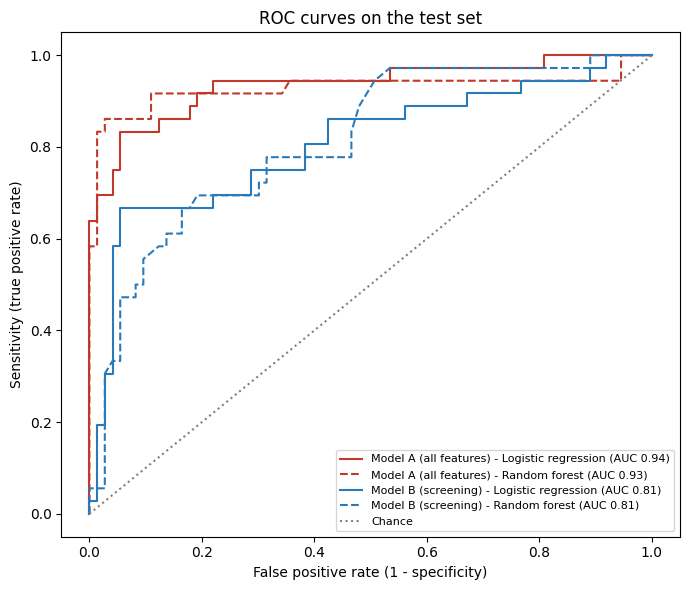

In [35]:
# I am plotting ROC curves for all four models on the test set
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(7, 6))
styles = {"Model A (all features) - Logistic regression": ("#c0392b", "-"),
          "Model A (all features) - Random forest":       ("#c0392b", "--"),
          "Model B (screening) - Logistic regression":    ("#2a7ab9", "-"),
          "Model B (screening) - Random forest":          ("#2a7ab9", "--")}

for key, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    color, line = styles[key]
    ax.plot(fpr, tpr, color=color, linestyle=line, label=f"{key} (AUC {roc_auc_score(y_test, p):.2f})")

ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Chance")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("Sensitivity (true positive rate)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("fig5_roc_curves.png", dpi=150)
plt.show()

**ROC curves:** Model A (red) reaches about 80–85% sensitivity at a false positive rate of only 5%. Model B (blue) reaches about 65% sensitivity at the same false positive rate, and needs a false positive rate of about 50% to reach 95% sensitivity. The curves are step-shaped because the test set is small (109 women). Within each feature set, logistic regression and random forest overlap closely.

### 6.3 Confusion matrices, sensitivity and specificity

I am showing how many women each logistic regression model classified correctly and incorrectly at a cut-off of 0.5. I also calculate sensitivity (PCOS cases correctly detected) and specificity (non-PCOS women correctly cleared) for all four models, because these are the measures clinicians use.

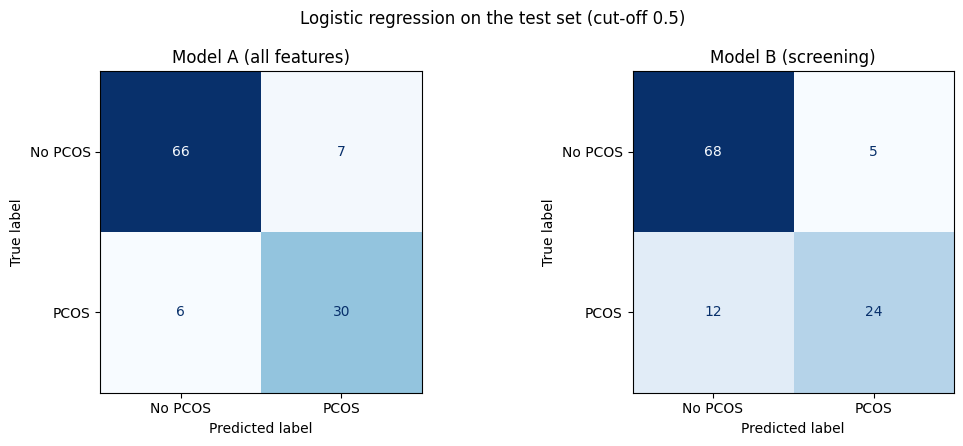

In [36]:
# I am drawing confusion matrices for the two logistic regression models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

lr_keys = ["Model A (all features) - Logistic regression",
           "Model B (screening) - Logistic regression"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, key in zip(axes, lr_keys):
    pred = (probs[key] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["No PCOS", "PCOS"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(key.replace(" - Logistic regression", ""))
    ax.grid(False)
plt.suptitle("Logistic regression on the test set (cut-off 0.5)")
plt.tight_layout()
plt.savefig("fig6_confusion_matrices.png", dpi=150)
plt.show()

In [37]:
# I am calculating sensitivity, specificity, PPV and NPV for all four models
rows = []
for key, p in probs.items():
    tn, fp, fn, tp = confusion_matrix(y_test, (p >= 0.5).astype(int)).ravel()
    rows.append({"Model": key,
                 "Sensitivity": round(tp / (tp + fn), 3),
                 "Specificity": round(tn / (tn + fp), 3),
                 "PPV": round(tp / (tp + fp), 3),
                 "NPV": round(tn / (tn + fn), 3)})
pd.DataFrame(rows)

,Model,Sensitivity,Specificity,PPV,NPV
0,Model A (all features) - Logistic regression,0.833,0.904,0.811,0.917
1,Model A (all features) - Random forest,0.833,0.986,0.968,0.923
2,Model B (screening) - Logistic regression,0.667,0.932,0.828,0.850
3,Model B (screening) - Random forest,0.556,0.904,0.741,0.805


**Confusion matrices:** At a cut-off of 0.5, Model A detects 30 of 36 PCOS cases (sensitivity 83%) and correctly clears 66 of 73 women without PCOS (specificity 90%). Model B detects only 24 of 36 cases (sensitivity 67%) while keeping specificity high (93%). For a screening tool, missing one in three cases is too many, so I adjust Model B's cut-off in the next step.

### 6.4 Choosing a screening cut-off for Model B

For screening, I want high sensitivity: a missed case is worse than an extra ultrasound. I choose the cut-off that gives at least 90% sensitivity. To avoid tuning on the test set, I choose the cut-off using cross-validated predictions on the training set only, and then apply it once to the test set.

In [38]:
# I am getting cross-validated probabilities for the training women (the test set stays untouched)
from sklearn.model_selection import cross_val_predict

key_b = "Model B (screening) - Logistic regression"
train_probs = cross_val_predict(make_models()["Logistic regression"],
                                X_screen.loc[train_idx], y_train,
                                cv=cv, method="predict_proba")[:, 1]

# I am finding the highest cut-off that still gives at least 90% sensitivity on the training data
fpr, tpr, thresholds = roc_curve(y_train, train_probs)
screen_cutoff = thresholds[tpr >= 0.90][0]
print(f"Screening cut-off chosen on training data: {screen_cutoff:.3f}")

Screening cut-off chosen on training data: 0.094


In [39]:
# I am applying the screening cut-off once to the test set and comparing it with 0.5
rows = []
for name, cut in [("Cut-off 0.5", 0.5), (f"Screening cut-off {screen_cutoff:.2f}", screen_cutoff)]:
    tn, fp, fn, tp = confusion_matrix(y_test, (probs[key_b] >= cut).astype(int)).ravel()
    rows.append({"Model B cut-off": name, "PCOS caught": f"{tp}/{tp + fn}",
                 "Sensitivity": round(tp / (tp + fn), 3),
                 "Specificity": round(tn / (tn + fp), 3),
                 "False alarms": fp})
pd.DataFrame(rows)

,Model B cut-off,PCOS caught,Sensitivity,Specificity,False alarms
0,Cut-off 0.5,24/36,0.667,0.932,5
1,Screening cut-off 0.09,32/36,0.889,0.384,45


**Screening cut-off:** I chose a cut-off of 0.09 on the training data to reach about 90% sensitivity. On the test set it detects 32 of 36 PCOS cases (sensitivity 89%), so the choice generalised well. However, specificity falls to 38%: 45 women without PCOS are flagged, and 77 of 109 women in total would be referred for ultrasound. Without the Rotterdam features, Model B is therefore a modest triage aid. It could spare about 30% of women an ultrasound while missing few cases, but it cannot replace clinical and ultrasound assessment.

### 6.5 Which features matter most?

I am converting the logistic regression coefficients into odds ratios. Because I scaled the features, each odds ratio shows how the odds of PCOS change when that feature increases by one standard deviation. An odds ratio above 1 means higher odds of PCOS; below 1 means lower odds.

In [50]:
# I am checking whether a few extreme progesterone values drive the model's result
print(df.groupby("PCOS (Y/N)")["PRG(ng/mL)"].describe().round(2))
print("\nHighest progesterone values:")
print(df.nlargest(8, "PRG(ng/mL)")[["PCOS (Y/N)", "PRG(ng/mL)"]])

            count  mean   std   min   25%   50%   75%   max
PCOS (Y/N)                                                 
0           364.0  0.73  4.64  0.11  0.25  0.31  0.46  85.0
1           177.0  0.37  0.17  0.05  0.25  0.32  0.43   1.1

Highest progesterone values:
     PCOS (Y/N)  PRG(ng/mL)
41            0       85.00
484           0       25.30
121           0        6.39
410           0        4.25
64            0        3.66
164           0        1.26
350           0        1.24
71            0        1.22


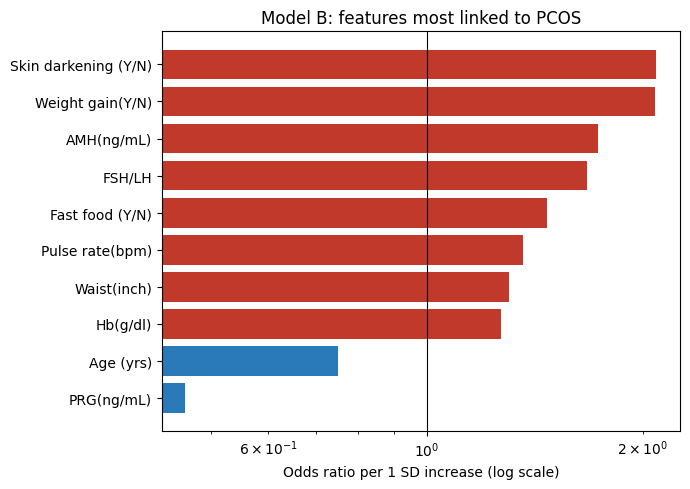

In [41]:
# I am plotting the top 10 odds ratios for Model B (the screening model)
top_b = top(or_b).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#c0392b" if v > 1 else "#2a7ab9" for v in top_b.values]
ax.barh(top_b.index, top_b.values, color=colors)
ax.axvline(1, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("Odds ratio per 1 SD increase (log scale)")
ax.set_title("Model B: features most linked to PCOS")
plt.tight_layout()
plt.savefig("fig7_odds_ratios.png", dpi=150)
plt.show()

**Feature importance:** In Model A, the Rotterdam criteria dominate (right follicle count OR 5.98, hirsutism 2.19, irregular cycle 1.94), confirming that the full model largely re-learns the diagnosis.

In my first version of Model B, two odds ratios contradicted the raw data: the FSH/LH ratio (OR 1.67, although the raw ratio was lower in PCOS) and progesterone (OR 0.46, although median progesterone was the same in both groups). Both were driven by a few extreme values. I investigated them in 6.6 to 6.8 and removed both variables from the final model.

### 6.6 Checking an unexpected result: FSH/LH

In PCOS, LH is typically raised relative to FSH, so I expect a lower FSH/LH ratio in women with PCOS (odds ratio below 1). My model shows an odds ratio of 1.67, the opposite direction. I am checking whether this comes from the raw data or from the model.

In [42]:
# I am comparing FSH, LH and the FSH/LH ratio between the groups
check = df.groupby("PCOS (Y/N)")[["FSH(mIU/mL)", "LH(mIU/mL)", "FSH/LH"]].median().round(2)
check.index = ["No PCOS", "PCOS"]
print("Medians by group:\n", check, "\n")

# I am looking at the highest FSH/LH values, which may be driven by very low LH
print(df["FSH/LH"].describe().round(2))
print("\nLowest LH values:", sorted(df["LH(mIU/mL)"].unique())[:8])

Medians by group:
          FSH(mIU/mL)  LH(mIU/mL)  FSH/LH
No PCOS         4.99        2.30    2.36
PCOS            4.48        2.22    2.04 

count    541.00
mean       4.37
std       14.90
min        0.23
25%        1.42
50%        2.16
75%        3.94
max      327.00
Name: FSH/LH, dtype: float64

Lowest LH values: [np.float64(0.02), np.float64(0.032), np.float64(0.09), np.float64(0.1), np.float64(0.13), np.float64(0.15), np.float64(0.17), np.float64(0.2)]


**FSH/LH check:** In the raw data, the median FSH/LH ratio is lower in women with PCOS (2.04 vs 2.36), as expected physiologically. The model's odds ratio of 1.67 is therefore an artefact. The ratio is highly skewed (median 2.16, maximum 327), because dividing by very low LH values (as low as 0.02 mIU/mL) creates extreme outliers. LH values this low are implausible in women of reproductive age, and median LH barely differs between the groups, even though raised LH is a recognised feature of PCOS. This may reflect differences in the cycle day of sampling or in laboratory methods, and it is a limitation of the dataset.

### 6.7 Sensitivity analysis: removing the FSH/LH ratio

I am refitting Model B (logistic regression) without the FSH/LH ratio, keeping FSH and LH as separate features. I check whether performance and the main findings change. If they do not, my conclusions are robust to this problematic variable.

In [43]:
# I am refitting Model B without the FSH/LH ratio, on the same training and test women
X_screen_noratio = X_screen.drop(columns=["FSH/LH"])

lr_noratio = make_models()["Logistic regression"]
lr_noratio.fit(X_screen_noratio.loc[train_idx], y_train)
p_noratio = lr_noratio.predict_proba(X_screen_noratio.loc[test_idx])[:, 1]

print(f"Model B test AUC with FSH/LH ratio:    {roc_auc_score(y_test, probs[key_b]):.3f}")
print(f"Model B test AUC without FSH/LH ratio: {roc_auc_score(y_test, p_noratio):.3f}")

Model B test AUC with FSH/LH ratio:    0.806
Model B test AUC without FSH/LH ratio: 0.810


In [44]:
# I am checking the new odds ratios, including FSH and LH separately
or_noratio = pd.Series(np.exp(lr_noratio.named_steps["model"].coef_[0]), index=X_screen_noratio.columns)
print("Top 10 odds ratios without the ratio:\n", top(or_noratio))
print("\nFSH and LH:\n", or_noratio[["FSH(mIU/mL)", "LH(mIU/mL)"]].round(2))

Top 10 odds ratios without the ratio:
 PRG(ng/mL)              0.46
Weight gain(Y/N)        2.10
Skin darkening (Y/N)    2.09
AMH(ng/mL)              1.76
Fast food (Y/N)         1.47
Pulse rate(bpm)         1.36
Age (yrs)               0.77
Waist(inch)             1.28
Hb(g/dl)                1.27
No. of aborptions       0.81
dtype: float64

FSH and LH:
 FSH(mIU/mL)    1.04
LH(mIU/mL)     1.04
dtype: float64


**Sensitivity analysis:** Removing the FSH/LH ratio did not change Model B's performance (test AUC 0.806 with the ratio, 0.810 without), and the main predictors stayed the same: low progesterone (OR 0.46), weight gain (2.10), skin darkening (2.09) and AMH (1.76). FSH and LH alone had almost no effect (OR 1.04 each), consistent with the lack of LH difference between groups in this dataset. Because the simpler model performs equally well and avoids a misleading result, I prefer Model B without the FSH/LH ratio.

**Progesterone check:** The median progesterone was the same in both groups (0.31 vs 0.32 ng/mL). The model's odds ratio of 0.46 was driven by 5 women without PCOS who had high progesterone (3.7 to 85 ng/mL), consistent with luteal-phase sampling after ovulation (or, for the highest value, possible pregnancy). Because the cycle day of sampling is not recorded, progesterone cannot be interpreted reliably in this dataset. I therefore remove it, together with the FSH/LH ratio, from my final screening model.

### 6.8 Final screening model

I am refitting Model B (logistic regression) without the FSH/LH ratio and without progesterone. I check its performance on the test set and its odds ratios.

In [51]:
# I am building my final screening model without the FSH/LH ratio and progesterone
X_final = X_screen.drop(columns=["FSH/LH", "PRG(ng/mL)"])

lr_final = make_models()["Logistic regression"]
lr_final.fit(X_final.loc[train_idx], y_train)
p_final = lr_final.predict_proba(X_final.loc[test_idx])[:, 1]

print("Features in final Model B:", X_final.shape[1])
print(f"Original Model B test AUC: {roc_auc_score(y_test, probs[key_b]):.3f}")
print(f"Final Model B test AUC:    {roc_auc_score(y_test, p_final):.3f}")

Features in final Model B: 29
Original Model B test AUC: 0.806
Final Model B test AUC:    0.805


In [52]:
# I am showing the top 10 odds ratios of my final screening model
or_final = pd.Series(np.exp(lr_final.named_steps["model"].coef_[0]), index=X_final.columns)
top(or_final)

,0
Weight gain(Y/N),2.10
Skin darkening (Y/N),2.09
AMH(ng/mL),1.77
Fast food (Y/N),1.47
Pulse rate(bpm),1.38
Waist(inch),1.32
Age (yrs),0.78
Hb(g/dl),1.27
No. of aborptions,0.81
II beta-HCG(mIU/mL),1.19


In [53]:
# I am checking my final model at the screening cut-off, chosen again on training data only
train_probs_final = cross_val_predict(make_models()["Logistic regression"],
                                      X_final.loc[train_idx], y_train,
                                      cv=cv, method="predict_proba")[:, 1]
fpr, tpr, thresholds = roc_curve(y_train, train_probs_final)
cut_final = thresholds[tpr >= 0.90][0]

tn, fp, fn, tp = confusion_matrix(y_test, (p_final >= cut_final).astype(int)).ravel()
print(f"Screening cut-off: {cut_final:.3f}")
print(f"PCOS caught: {tp}/{tp + fn} | Sensitivity: {tp / (tp + fn):.3f} | "
      f"Specificity: {tn / (tn + fp):.3f} | Referred for ultrasound: {tp + fp}/{len(y_test)}")

Screening cut-off: 0.098
PCOS caught: 32/36 | Sensitivity: 0.889 | Specificity: 0.384 | Referred for ultrasound: 77/109


**Final screening model:** Without the FSH/LH ratio and progesterone, Model B keeps the same performance (test AUC 0.805 vs 0.806). Its strongest predictors are weight gain (OR 2.10) and skin darkening (OR 2.09), both signs of insulin resistance; raised AMH (OR 1.77), a blood marker of follicle number; fast food intake (OR 1.47); waist size (OR 1.32); and younger age (OR 0.78). All of these agree in direction with the raw group comparisons. Weaker effects (pulse, haemoglobin, number of abortions, β-hCG) have no clear clinical explanation and may reflect chance. At a screening cut-off chosen on training data, the final model detects 32 of 36 PCOS cases (sensitivity 89%) with a specificity of 38%, referring 77 of 109 women for ultrasound.

## Step 7: Summary of findings

**Data:** 541 women from 10 hospitals in Kerala, India; 177 (33%) diagnosed with PCOS.

**Data cleaning:** I standardised column names, removed ID columns and a leftover Excel column, converted text to numbers, and filled a small number of missing values with the median. I reviewed 10 implausible values clinically: I corrected 2 blood pressure typing errors, set 6 impossible values to missing, and kept 2 extreme but genuine values (AMH 66 ng/mL in a PCOS patient; TSH 65 mIU/L in a patient with hypothyroidism). I handled an undocumented cycle code without using the PCOS diagnosis, to avoid data leakage.

**Exploration:** Women with PCOS were younger and had a higher BMI, nearly double the AMH, and more than twice the follicle count. Weight gain, skin darkening, excess hair growth and irregular cycles were far more common. LH did not differ between groups, and progesterone was low in both, suggesting that the cycle day of blood sampling varied or was mostly follicular.

**Model A (all features):** Logistic regression reached a test AUC of 0.935 (sensitivity 83%, specificity 90%). This mainly reflects the Rotterdam diagnostic criteria, which the model largely re-learns.

**Final Model B (screening, without Rotterdam criteria):** Logistic regression reached a test AUC of 0.805. At a screening cut-off, it detected 89% of PCOS cases but referred 71% of women for ultrasound. It is a modest triage aid, not a replacement for clinical and ultrasound assessment. Its strongest predictors (weight gain, skin darkening, AMH, waist size) reflect insulin resistance and follicle number.

**Checking the model against the data:** Two odds ratios in my first screening model (FSH/LH ratio and progesterone) contradicted the raw data. Both were driven by a few extreme values, so I removed them. Performance did not change, and the final model's predictors all agree with the raw comparisons.

**Logistic regression vs random forest:** Both performed similarly on the test set, so I prefer logistic regression for its clinical interpretability.

## Limitations

- **Small sample:** 541 women and only 109 in the test set, so small differences between models are not reliable.
- **Single region:** all data comes from Kerala, so results need external validation before use elsewhere.
- **Hormone timing unknown:** the cycle day of blood sampling is not recorded. This makes progesterone, LH and FSH hard to interpret, and may explain why LH did not differ between groups.
- **Partial overlap with the diagnosis:** AMH reflects follicle number, so the screening model is not entirely free of diagnostic information.
- **Self-reported features:** symptoms and lifestyle are self-reported, and some (such as exercise) may reflect advice given after diagnosis.
- **Associations, not causes:** odds ratios show adjusted associations and do not prove that a feature causes PCOS.